# Basic FIR filters and cosine-modulated filter banks

**Learning goals:** design a low-pass FIR filter, inspect its impulse/frequency response, listen to filtered audio, build cosine-modulated subbands from a low-pass prototype, and evaluate the sum of the subbands.

The filter bank below is a **simple educational cosine-modulated FIR bank**, *not* a perfect-reconstruction or critically sampled filter bank. There is no downsampling. Summing its outputs approximates a delayed original signal; reconstruction quality depends on the prototype length and cutoff.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from scipy import signal
from scipy.io import wavfile
from pathlib import Path

EPS = np.finfo(float).tiny


def read_sound(path, fallback='noise', fs=44100):
    """Load a mono WAV as floating-point audio; generate a demo if it is absent.

    Integer PCM is mapped approximately to [-1, 1). Stereo is averaged to mono.
    """
    path = Path(path)
    if not path.exists():
        print(f'{path} not found; using a synthetic {fallback} example.')
        duration = 1.5
        t = np.arange(round(duration * fs)) / fs
        if fallback == 'noise':
            x = 0.2 * np.random.default_rng(0).standard_normal(t.size)
        else:
            x = 0.25 * (np.sin(2*np.pi*110*t) + 0.5*np.sin(2*np.pi*220*t)
                        + 0.25*np.sin(2*np.pi*330*t))
        return x, fs
    rate, x = wavfile.read(path)
    if np.issubdtype(x.dtype, np.integer):
        info = np.iinfo(x.dtype)
        if info.min < 0:
            x = x.astype(np.float64) / max(abs(info.min), info.max)
        else:
            x = (x.astype(np.float64) - (info.max+1)/2) / ((info.max+1)/2)
    else:
        x = x.astype(np.float64)
    if x.ndim == 2:
        x = x.mean(axis=1)
    return x, rate


def listen(x, fs):
    """Play at the actual sample rate without separately normalizing signals."""
    display(Audio(x, rate=int(fs), normalize=False))


def display_sound(x, fs):
    t = np.arange(len(x))/fs
    plt.figure(figsize=(10, 3))
    plt.plot(t, x)
    plt.xlabel('Time (s)'); plt.ylabel('Amplitude'); plt.tight_layout(); plt.show()


def display_spectrum(x, fs):
    """Single-sided windowed amplitude spectrum; values relative to full scale."""
    w = signal.windows.hann(len(x), sym=False)
    X = np.fft.rfft(x * w)
    magnitude = np.abs(X) / max(w.sum()/2, EPS)
    f = np.fft.rfftfreq(len(x), d=1/fs)
    plt.figure(figsize=(10, 3))
    plt.plot(f, 20*np.log10(np.maximum(magnitude, EPS)))
    plt.xlabel('Frequency (Hz)'); plt.ylabel('Magnitude (dBFS approx.)')
    plt.tight_layout(); plt.show()


def display_spectrogram(x, fs, fft_size=1024, hop_size=512):
    """Plot a properly indexed STFT magnitude spectrogram."""
    f, t, z = signal.stft(x, fs=fs, window='hann', nperseg=fft_size,
                          noverlap=fft_size-hop_size, boundary=None, padded=False)
    plt.figure(figsize=(10, 3.5))
    plt.pcolormesh(t, f, 20*np.log10(np.maximum(np.abs(z), EPS)),
                   shading='auto', cmap='inferno', vmin=-90)
    plt.xlabel('Time (s)'); plt.ylabel('Frequency (Hz)')
    plt.colorbar(label='Magnitude (dB)'); plt.tight_layout(); plt.show()


def plot_freq_response(h, fs, title):
    f, H = signal.freqz(h, worN=4096, fs=fs)
    plt.figure(figsize=(10, 3.5))
    plt.plot(f, 20*np.log10(np.maximum(np.abs(H), EPS)))
    plt.ylim(-100, 10); plt.grid(alpha=0.3)
    plt.xlabel('Frequency (Hz)'); plt.ylabel('Gain (dB)')
    plt.title(title); plt.tight_layout(); plt.show()


def prototype_filter(num_taps, num_bands):
    """Prototype for a uniformly spaced cosine-modulated bank.

    Band spacing is fs/(2L); the prototype cutoff is fs/(4L).
    With SciPy's normalized-to-Nyquist firwin cutoff this is 1/(2L).
    An odd number of taps gives an integer group delay.
    """
    if num_taps % 2 != 1:
        raise ValueError('Use an odd number of taps for a centered linear-phase prototype.')
    return signal.firwin(num_taps, 1/(2*num_bands), window='hamming')


def modulate_filter(h, num_bands, band):
    """Cosine modulation; band centers: (k + 1/2) * fs / (2L)."""
    if not 0 <= band < num_bands:
        raise ValueError('Band index must lie in [0, num_bands).')
    n = np.arange(len(h))
    delay = (len(h)-1)/2
    return 2*h*np.cos(np.pi*(2*band+1)*(n-delay)/(2*num_bands))


## 1. FIR low-pass filter

A finite impulse response (FIR) filter computes a weighted sum of current and previous samples. `firwin` designs a linear-phase low-pass impulse response using a windowed sinc. Its cutoff is in **Hz** when `fs` is passed.

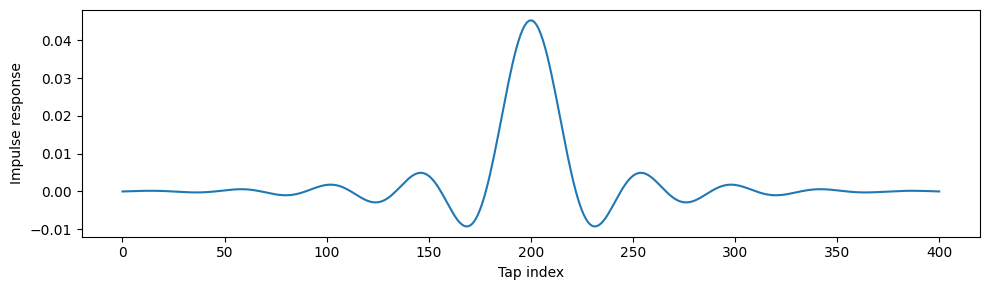

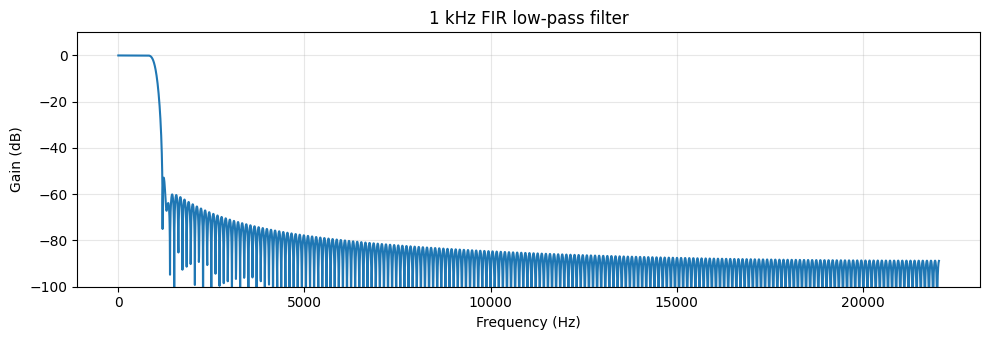

In [2]:
# A 1 kHz low-pass example (independent of the filter-bank prototype).
fs_design = 44100
lowpass_taps = 401
cutoff_hz = 1000
h_lp = signal.firwin(lowpass_taps, cutoff_hz, window='hamming', fs=fs_design)
plt.figure(figsize=(10, 3)); plt.plot(h_lp)
plt.xlabel('Tap index'); plt.ylabel('Impulse response'); plt.tight_layout(); plt.show()
plot_freq_response(h_lp, fs_design, '1 kHz FIR low-pass filter')

## 2. Listen to the low-pass filter

Load white noise and compare the original and low-pass versions. **Important:** the filter coefficients above assume a 44.1 kHz sample rate. If the file has a different rate, redesign the filter for that rate. Playback uses a common gain and does not automatically normalize the two sounds.

Original noise:


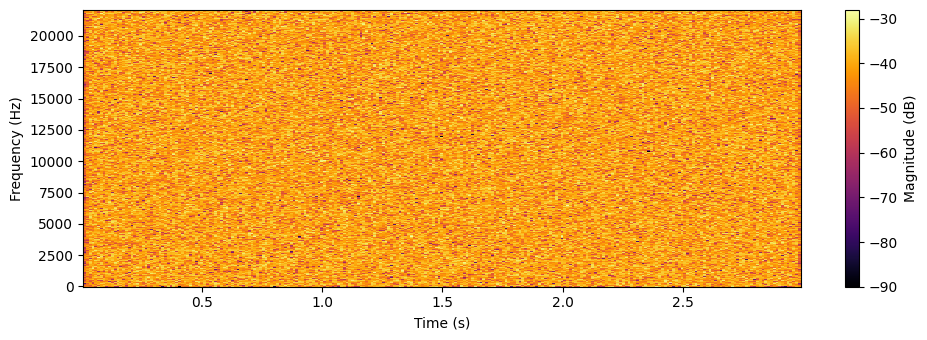

Low-pass filtered noise:


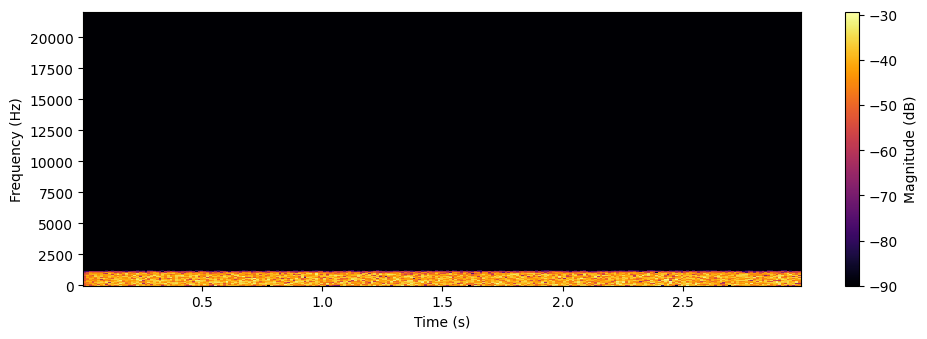

In [3]:
noise, fs_noise = read_sound('../sounds/white-noise.wav', fallback='noise')
if fs_noise != fs_design:
    h_lp = signal.firwin(lowpass_taps, cutoff_hz, window='hamming', fs=fs_noise)
lowpassed_noise = signal.lfilter(h_lp, [1.0], noise)
# A common gain avoids clipping and preserves the relative levels when listening.
gain = min(1.0, 0.95 / max(np.max(np.abs(noise)),
                                np.max(np.abs(lowpassed_noise)), EPS))
print('Original noise:'); listen(noise * gain, fs_noise)
display_spectrogram(noise, fs_noise)
print('Low-pass filtered noise:'); listen(lowpassed_noise * gain, fs_noise)
display_spectrogram(lowpassed_noise, fs_noise)

## 3. One frequency band of a cosine-modulated bank

We now design a **different** low-pass prototype with cutoff proportional to the number of bands. Modulation shifts it to a chosen center frequency. For `L` bands, the ideal centers are \(f_k=(k+1/2) f_s/(2L)\), for \(k=0,\ldots,L-1\). A longer prototype gives narrower transitions but also more delay.

Band 10 center: 7235.2 Hz, filter delay: 256 samples


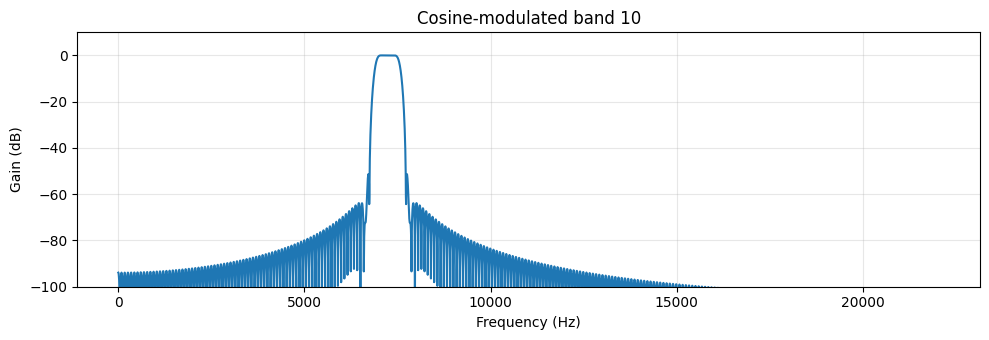

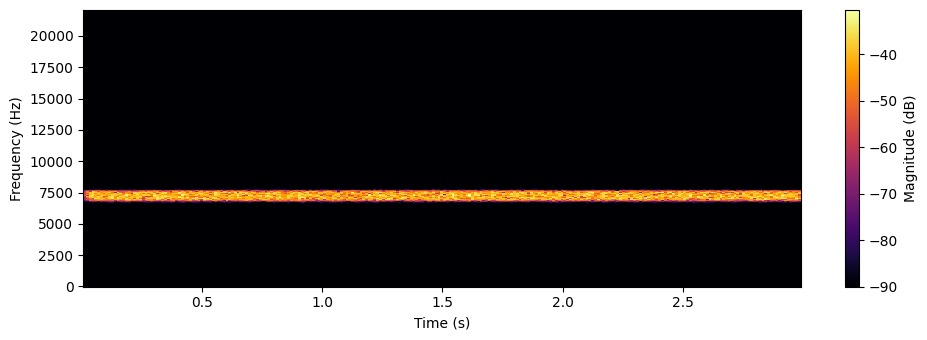

In [4]:
L = 32
N = 513  # Odd and much longer than 21 taps: useful stopband separation
k = 10
h_proto = prototype_filter(N, L)
h_band = modulate_filter(h_proto, L, k)
center_hz = (k + 0.5) * fs_noise / (2*L)
print(f'Band {k} center: {center_hz:.1f} Hz, filter delay: {(N-1)//2} samples')
plot_freq_response(h_band, fs_noise, f'Cosine-modulated band {k}')
y_band = signal.lfilter(h_band, [1.0], noise)
listen(y_band * gain, fs_noise)
display_spectrogram(y_band, fs_noise)

## 4. Analysis followed by simple summation

Filter the input with *every* band and add the outputs. No decimation or synthesis bank is used here: this is **not** a general perfect-reconstruction filter bank. A linear-phase FIR bank introduces a delay of \((N-1)/2\) samples. The sum should resemble a delayed copy of the input, but finite transition bands and ripple lead to errors.

Filter-bank delay: 256 samples (5.80 ms)
Relative RMS reconstruction error: 0.257%
Original (delay-aligned section):


Sum of subbands (delay compensated):


Reconstruction error (same playback gain):


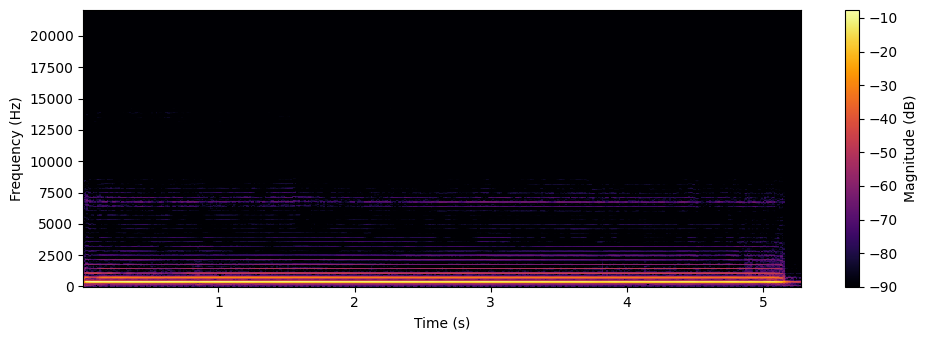

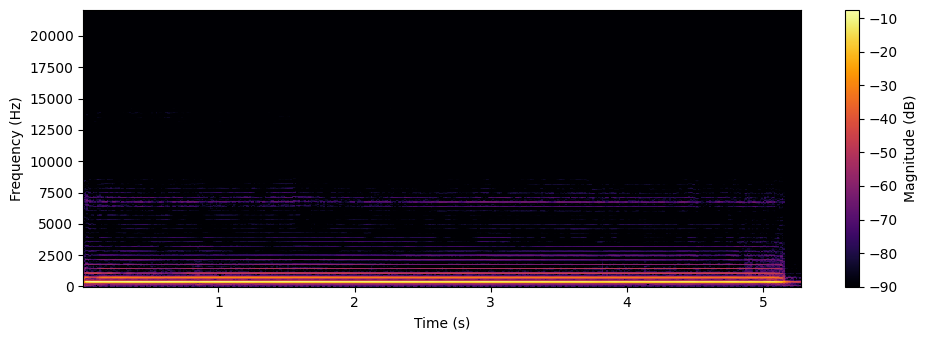

In [5]:
x, fs = read_sound('../sounds/406609-tuba.wav', fallback='harmonic')
L = 32
N = 513
h_proto = prototype_filter(N, L)
subbands = []
for k in range(L):
    hk = modulate_filter(h_proto, L, k)
    subbands.append(signal.lfilter(hk, [1.0], x))
y = np.sum(subbands, axis=0)
# The reconstructed output is delayed because each band has linear phase.
delay = (N - 1)//2
valid = min(len(x)-delay, len(y)-delay)
if valid > 0:
    aligned_original = x[:valid]
    aligned_reconstruction = y[delay:delay+valid]
    rms_error = np.sqrt(np.mean((aligned_original-aligned_reconstruction)**2))
    rms_reference = np.sqrt(np.mean(aligned_original**2))
    print(f'Filter-bank delay: {delay} samples ({delay/fs*1000:.2f} ms)')
    print(f'Relative RMS reconstruction error: {rms_error/max(rms_reference, EPS):.3%}')
    common_gain = min(1.0, 0.95/max(np.max(np.abs(aligned_original)),
                                      np.max(np.abs(aligned_reconstruction)), EPS))
    print('Original (delay-aligned section):'); listen(aligned_original * common_gain, fs)
    print('Sum of subbands (delay compensated):'); listen(aligned_reconstruction * common_gain, fs)
    print('Reconstruction error (same playback gain):')
    listen((aligned_original-aligned_reconstruction) * common_gain, fs)
    display_spectrogram(aligned_original, fs)
    display_spectrogram(aligned_reconstruction, fs)
else:
    print('Audio too short for the chosen prototype delay.')

## 5. Combined response of the bank

The frequency response of the **sum of filters** equals the sum of their **complex** frequency responses (not the sum of their magnitudes). An ideal delayed all-pass response would have 0 dB gain at every frequency. Small deviations indicate imperfect amplitude reconstruction. The large linear phase corresponds to a fixed time delay.

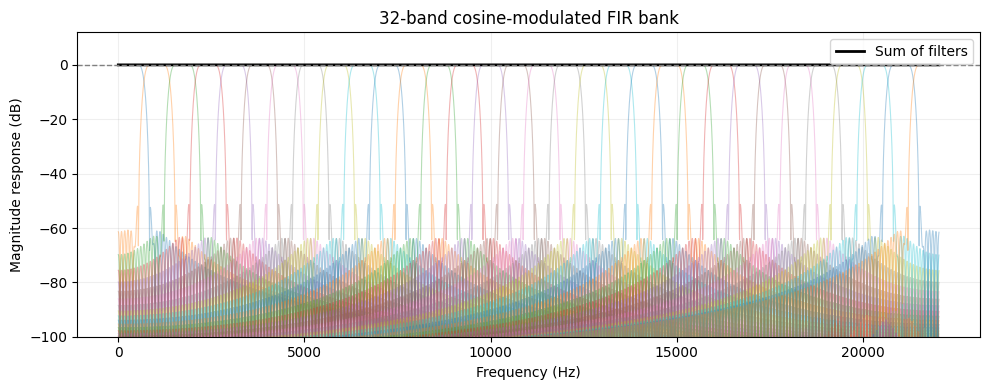

Combined center tap: 1.0026 (ideal delayed impulse: 1.0)


In [6]:
h_sum = np.zeros(N)
plt.figure(figsize=(10, 4))
for k in range(L):
    hk = modulate_filter(h_proto, L, k)
    h_sum += hk
    f, Hk = signal.freqz(hk, worN=4096, fs=fs)
    plt.plot(f, 20*np.log10(np.maximum(np.abs(Hk), EPS)), alpha=0.35, lw=0.8)
f, Hsum = signal.freqz(h_sum, worN=4096, fs=fs)
plt.plot(f, 20*np.log10(np.maximum(np.abs(Hsum), EPS)), 'k', lw=2,
         label='Sum of filters')
plt.axhline(0, color='gray', ls='--', lw=1)
plt.xlabel('Frequency (Hz)'); plt.ylabel('Magnitude response (dB)')
plt.ylim(-100, 12); plt.title(f'{L}-band cosine-modulated FIR bank')
plt.grid(alpha=0.2); plt.legend(); plt.tight_layout(); plt.show()
print(f'Combined center tap: {h_sum[delay]:.4f} (ideal delayed impulse: 1.0)')

## What to remember

- **FIR filtering** is convolution with an impulse response; cutoff and sample rate must be consistent.
- **A prototype** is a low-pass filter used to construct multiple modulated passbands. Do not confuse it with the independent 1 kHz low-pass example.
- **Cosine modulation** shifts the prototype into approximately uniformly spaced frequency bands.
- **Summing subband outputs** here approximates the original with a fixed delay, but the bank is **not guaranteed perfect reconstruction**.
- **Spectra, listening, and numerical error** provide complementary ways to evaluate the result.

**Try:** change `N` to 129, 257, or 1025 (odd values), then compare band separation, group delay, summed response, and reconstruction error.